# Cas 04 : Attaques de la chaîne d'approvisionnement logicielle — QUT-DV25

**Dataset :** QUT-DV25 : traces de comportement (analyse dynamique) de paquets Python (PyPI) à l'installation et après l'installation.

**Modèles :** CatBoost et Explainable Boosting Machine (EBM).

**L’objectif** est de détecter automatiquement si un paquet logiciel est malveillant ou bénin, d’après son comportement à l’installation et après l’installation. C’est un problème de classification binaire supervisée (malveillant = 1, bénin = 0).

**Plan :** 0. Environnement, 1. Chargement et exploration, 2. Sélection des variables, 3. Préparation des données, 4. CatBoost, 5. EBM, 6. Évaluation, 7. Comparaison, 8. Seuil de décision, 9. Interprétabilité, 10. Conclusion.

In [1]:
!pip install -q catboost interpret python-docx

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 0. Environnement expérimental
Bibliothèques, versions et graine aléatoire (`SEED = 42`) utilisées pour toutes les expériences.

In [2]:
import sys, re, time, json, platform, warnings, zipfile, hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn, catboost, interpret
from scipy.stats import mannwhitneyu
from IPython.display import display

from catboost import CatBoostClassifier, Pool
from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, matthews_corrcoef, confusion_matrix,
                             roc_curve, precision_recall_curve, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme()
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)
SEED = 42

ENV = {"Python": sys.version.split()[0], "Plateforme": platform.platform(),
       "Exécution": "Google Colab" if "google.colab" in sys.modules else "Local",
       "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
       "catboost": catboost.__version__, "interpret (EBM)": interpret.__version__, "random_state": SEED}
display(pd.Series(ENV, name="valeur").to_frame())

,valeur
Python,3.13.18
Plateforme,Linux-6.6.159+-x86_64-with-glibc2.39
Exécution,Google Colab
numpy,2.4.6
pandas,2.2.3
scikit-learn,1.6.1
catboost,1.2.10
interpret (EBM),0.7.8
random_state,42


## 1. Charger et explorer le dataset
Le zip contient un CSV par famille de traces. Chaque CSV est lu, sa famille est déduite de son nom (`QUT-DV25_<Famille>_Traces.csv`), puis tous sont **fusionnés sur `Package_Name`**. Un paquet absent d'une famille (par ex. aucune activité réseau) reçoit la valeur 0.

In [3]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DATA_PATH = Path("/content/drive/MyDrive/QUT-DV25_Datasets.zip")   # fichier .zip OU dossier contenant les .csv
except ImportError:
    DATA_PATH = Path("QUT-DV25_Datasets.zip")                          # exécution locale

ID_COL, LABEL_COL = "Package_Name", "Level"

def family_name(path):
    """Déduit la famille du nom de fichier : QUT-DV25_<Famille>_Traces.csv -> nom normalisé."""
    m = re.search(r"QUT-DV25_(.+?)_Traces", Path(path).name, re.I)
    raw_name = (m.group(1) if m else Path(path).stem).lower()
    for key, name in [("file", "Filetop"), ("install", "Install"), ("open", "Opensnoop"),
                      ("pattern", "Pattern"), ("tcp", "TCP"), ("sys", "SysCall")]:
        if key in raw_name: return name
    return m.group(1) if m else Path(path).stem

def read_csvs(path):
    """Retourne {famille: DataFrame} pour tous les CSV 'Traces' d'un zip ou d'un dossier."""
    out = {}
    if path.suffix.lower() == ".zip":
        with zipfile.ZipFile(path) as z:
            for info in z.infolist():
                if info.filename.lower().endswith(".csv") and "_traces" in info.filename.lower():
                    with z.open(info) as f: out[family_name(info.filename)] = pd.read_csv(f)
    else:
        for p in sorted(path.rglob("*.csv")):
            if "_traces" in p.name.lower(): out[family_name(p)] = pd.read_csv(p)
    return out

if not DATA_PATH.exists():
    raise FileNotFoundError(f"{DATA_PATH} introuvable : vérifiez DATA_PATH.")
tables = read_csvs(DATA_PATH)
if not tables:
    raise ValueError("Aucun fichier *_Traces.csv trouvé dans " + str(DATA_PATH))

print("Fichiers chargés :")
for fam, t in tables.items():
    print(f"  {fam:10s} | {t.shape[0]:6d} lignes | {t.shape[1] - 2:3d} variables | paquets distincts : {t[ID_COL].nunique()}")

Mounted at /content/drive
Fichiers chargés :
  Filetop    |  14271 lignes |   9 variables | paquets distincts : 14271
  Install    |  14271 lignes |   6 variables | paquets distincts : 14271
  Opensnoop  |  14271 lignes |  12 variables | paquets distincts : 14271
  Pattern    |  14271 lignes |  10 variables | paquets distincts : 14271
  SysCall    |  14271 lignes |  33 variables | paquets distincts : 14271
  TCP        |  14271 lignes |   8 variables | paquets distincts : 14271


Dimensions après fusion : (14271, 80)
Variables par famille : {'SysCall': 33, 'Opensnoop': 12, 'Pattern': 10, 'Filetop': 9, 'TCP': 8, 'Install': 6}
Valeurs brutes du label : [1, 0]
Légitimes (0) : 7144 | Malveillants (1) : 7127
Valeurs manquantes : 81432 | paquets dupliqués : 0


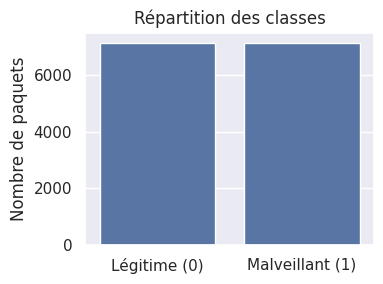

,Package_Name,Total_System_Calls,Unique_System_Calls,Unique_System_Calls_List,File_Operations,Unique_File_Operations,Unique_File_Operations_List,Memory_Operations,Unique_Memory_Operations,Unique_Memory_Operations_List,Network_Operations,Unique_Network_Operations,Unique_Network_Operations_List,Process_Management_Operations,Unique_Process_Management_Operations,Unique_Process_Management_Operations_List,IO_Operations,Unique_IO_Operations,Unique_IO_Operations_List,Time_Operations,Unique_Time_Operations,Unique_Time_Operations_List,IPC_Operations,Unique_IPC_Operations,Unique_IPC_Operations_List,Filesystem_Operations,Unique_Filesystem_Operations,Unique_Filesystem_Operations_List,Security_Operations,Unique_Security_Operations,Unique_Security_Operations_List,Miscellaneous_Operations,Unique_Miscellaneous_Operations,Unique_Miscellaneous_Operations_List,Level,Total_Reads,Total_Writes,Total_Read_Data_Transfer,Total_Write_Data_Transfer,Read_Processes,Write_Processes,Read_Data_Transfer_Processes,Write_Data_Transfer_Processes,File_Access_Processes,Total_Dependency_Count,Total_Dependencies,Direct_Dependency_Count,Direct_Dependencies,Indirect_Dependency_Count,Indirect_Dependencies,Total_Paths,Total_Error,Total_ File_Descriptor,Python_Related_Keywords,Install_Package_Keywords,Root_DIR_Installation,Temporary_DIR_Installation,Home_DIR_Installation,User_Access,Sys_Access,Etc_DIR_Installation,Other_DIR_Installation,Pattern_1,Pattern_2,Pattern_3,Pattern_4,Pattern_5,Pattern_6,Pattern_7,Pattern_8,Pattern_9,Pattern_10,Total_Entries,Unique_C-COMM,Python_Related_Process,State_Transition,Local_IP_Address_Access,Remote_IP_Address_Access,Local_Port_Access,Remote_Port_Access
0,10Cent10-999.0.4.tar.gz,4859,33,"munmap, newfstatat, openat, fstat, ioctl, lseek, read, close, mmap, mprotect, brk, getdents64, epoll_create1, futex,...",3945,12,"newfstatat, mkdir, fstat, write, unlink, read, rmdir, chmod, lseek, close, rename, openat",433,4,"munmap, mmap, mprotect, brk",2,2,"socket, bind",21,1,getpid,298,1,ioctl,0,0,NaN,0,0,NaN,0,0,NaN,0,0,NaN,7,2,"getrandom, uname",1,1345126.0,711470.0,273890605.0,580106.0,"opensnoop-bpfcc, filetop-bpfcc, tcpstates-bpfcc, pgrep, gnome-system-mo","opensnoop-bpfcc, strace, StreamTrans, Classif~date, sqldb:c~lite","opensnoop-bpfcc, filetop-bpfcc, pip, gnome-system-mo, tcpstates-bpfcc","StreamTrans, strace, Classif~date, pip, sqldb:c~lite","gnome-system-mo, pgrep, pip, StreamTrans, sqldb:c~lite",0,NaN,0,NaN,0,NaN,8045,8045,29,1083,2305,0,71,792,411,1225,151,5395,newfstatat -> newfstatat -> newfstatat,fstat -> ioctl -> lseek,openat -> fstat -> ioctl,newfstatat -> newfstatat -> openat,newfstatat -> openat -> fstat,newfstatat -> newfstatat -> newfstatat -> no-error -> no-fd,fstat -> ioctl -> lseek -> no-error -> no-fd,openat -> fstat -> ioctl -> no-error -> no-fd,ioctl -> lseek -> lseek -> error=ENOTTY -> no-fd,read -> read -> close -> no-error -> no-fd,946,7,316,"{'FIN_WAIT1 -> ->': 188, 'SYN_SENT -> ->': 187, 'FIN_WAIT2 -> ->': 181, 'CLOSE -> ->': 164, 'ESTABLISHED -> ->': 162...",2,62,194,21
1,10Cent11-999.0.4.tar.gz,1423,34,"read, getpid, ioctl, write, wait4, close, newfstatat, openat, fstat, fcntl, getdents64, lseek, unlinkat, rmdir, brk,...",1014,8,"newfstatat, write, fstat, read, rmdir, lseek, close, openat",25,4,"munmap, brk, mprotect, mmap",83,9,"socket, getpeername, connect, bind, recvfrom, sendto, getsockname, setsockopt, getsockopt",25,2,"wait4, getpid",97,2,"ioctl, poll",0,0,NaN,0,0,NaN,0,0,NaN,0,0,NaN,2,1,uname,1,1192399.0,585508.0,251798360.0,547692.0,"opensnoop-bpfcc, filetop-bpfcc, tcpstates-bpfcc, pgrep, gnome-system-mo","opensnoop-bpfcc, strace, StreamTrans, Classif~date, sqldb:c~lite","opensnoop-bpfcc, filetop-bpfcc, pip, gnome-system-mo, tcpstates-bpfcc","StreamTrans, strace, Classif~date, pip, sqldb:c~lite","gnome-system-mo, pgrep, pip, sqldb:c~lite, StreamTrans",0,NaN,0,NaN,0,NaN,4790,4790,12,1616,843,2,87,1118,721,1200,104,1558,newfstatat -> newfstatat -> newfstatat,read -> read -> read,newfstatat -> openat -> fstat,i

In [4]:
# --- Fusion des familles sur Package_Name ---
base_fam = "SysCall" if "SysCall" in tables else max(tables, key=lambda f: len(tables[f]))
raw = tables[base_fam].drop_duplicates(ID_COL).copy()
FAMILY_OF = {c: base_fam for c in raw.columns if c not in (ID_COL, LABEL_COL)}

for fam, t in tables.items():
    if fam == base_fam: continue
    t = t.drop(columns=[LABEL_COL]).drop_duplicates(ID_COL)
    renames = {c: f"{c}_{fam}" for c in t.columns if c != ID_COL and c in raw.columns}   # évite les collisions de noms
    t = t.rename(columns=renames)
    for c in t.columns:
        if c != ID_COL: FAMILY_OF[c] = fam
    raw = raw.merge(t, on=ID_COL, how="left")

print("Dimensions après fusion :", raw.shape)
print("Variables par famille :", pd.Series(FAMILY_OF).value_counts().to_dict())

# --- Label : 0 = légitime, 1 = malveillant ---
print("Valeurs brutes du label :", raw[LABEL_COL].unique().tolist())
lab = raw[LABEL_COL]
y_all = (lab.astype(int) if pd.api.types.is_numeric_dtype(lab)
         else lab.astype(str).str.lower().str.contains("mal").astype(int))
counts = y_all.value_counts().sort_index()
print(f"Légitimes (0) : {counts[0]} | Malveillants (1) : {counts[1]}")
print("Valeurs manquantes :", int(raw.isna().sum().sum()), "| paquets dupliqués :", int(raw.duplicated(ID_COL).sum()))

plt.figure(figsize=(4, 3))
sns.barplot(x=["Légitime (0)", "Malveillant (1)"], y=counts.values)
plt.title("Répartition des classes"); plt.ylabel("Nombre de paquets"); plt.tight_layout(); plt.show()
display(raw.head())

## 2. Caractéristiques décrivant le comportement des paquets
Chaque variable appartient à une des 6 familles de traces eBPF. Les colonnes textuelles (listes d'appels, dépendances, IP, ports, transitions TCP…) sont converties en **nombre d'éléments** pour obtenir des variables numériques.

In [5]:
FEATURE_COLS = list(FAMILY_OF)

def to_number(v):
    """Nombre tel quel ; '2 (a, b)' -> 2 ; liste écrite en texte -> nombre d'éléments ; vide -> 0."""
    if pd.isna(v): return 0.0
    if isinstance(v, (int, float, np.integer, np.floating, bool, np.bool_)): return float(v)
    s = str(v).strip()
    try: return float(s)
    except ValueError: pass
    m = re.match(r"^(\d+(?:\.\d+)?)\s*\(", s)
    if m: return float(m.group(1))
    s = s.strip("[](){}").strip()
    return 0.0 if s == "" else float(len([t for t in re.split(r"[,;|]", s) if t.strip()]))

X_num = raw[FEATURE_COLS].copy()
converted = [c for c in FEATURE_COLS if not pd.api.types.is_numeric_dtype(X_num[c])]
for c in converted: X_num[c] = X_num[c].map(to_number)
X_num = X_num.astype(float).fillna(0.0)   # paquet absent d'une famille / valeur manquante = aucune activité
print("Colonnes texte converties en comptage :", converted)

FAMILY_INFO = {  # (ce que mesure la famille, pourquoi c'est utile en sécurité)
    "Filetop":   ("lectures et écritures de fichiers", "une activité de fichiers anormale peut révéler une exfiltration de données ou le dépôt de fichiers malveillants"),
    "Install":   ("dépendances installées avec le paquet", "un paquet peut introduire indirectement une dépendance compromise"),
    "Opensnoop": ("ouvertures de fichiers par zone du système", "l'accès à des zones sensibles (/root, /etc, /sys) est inhabituel pour un simple paquet"),
    "TCP":       ("connexions réseau (IP, ports, états)", "des connexions vers de nombreux serveurs ou ports inhabituels peuvent indiquer un accès à distance ou une exfiltration"),
    "SysCall":   ("appels système par catégorie", "beaucoup d'appels liés aux droits ou aux processus peut indiquer une élévation de privilèges ou le lancement de programmes cachés"),
    "Pattern":   ("séquences d'appels système récurrentes", "certaines séquences correspondent à des comportements typiques d'attaque (lancer un programme, ouvrir un port d'écoute)"),
}
def group_of(col):
    return FAMILY_OF.get(col, "Autre")

groups_table = pd.DataFrame({"variable": FEATURE_COLS, "famille": [group_of(c) for c in FEATURE_COLS],
                             "min": X_num.min().values, "médiane": X_num.median().values, "max": X_num.max().values})
display(groups_table.sort_values(["famille", "variable"]).reset_index(drop=True))
display(groups_table["famille"].value_counts().to_frame("nb variables"))

Colonnes texte converties en comptage : ['Unique_System_Calls_List', 'Unique_File_Operations_List', 'Unique_Memory_Operations_List', 'Unique_Network_Operations_List', 'Unique_Process_Management_Operations_List', 'Unique_IO_Operations_List', 'Unique_Time_Operations_List', 'Unique_IPC_Operations_List', 'Unique_Filesystem_Operations_List', 'Unique_Security_Operations_List', 'Unique_Miscellaneous_Operations_List', 'Read_Processes', 'Write_Processes', 'Read_Data_Transfer_Processes', 'Write_Data_Transfer_Processes', 'File_Access_Processes', 'Total_Dependencies', 'Direct_Dependencies', 'Indirect_Dependencies', 'Pattern_1', 'Pattern_2', 'Pattern_3', 'Pattern_4', 'Pattern_5', 'Pattern_6', 'Pattern_7', 'Pattern_8', 'Pattern_9', 'Pattern_10', 'State_Transition']


,variable,famille,min,médiane,max
0,File_Access_Processes,Filetop,0.0,5.0,5.000000e+00
1,Read_Data_Transfer_Processes,Filetop,0.0,5.0,5.000000e+00
2,Read_Processes,Filetop,0.0,5.0,5.000000e+00
3,Total_Read_Data_Transfer,Filetop,0.0,145196635.0,1.132390e+09
4,Total_Reads,Filetop,0.0,846608.0,7.067315e+07
...,...,...,...,...,...
73,Remote_IP_Address_Access,TCP,0.0,33.0,3.369000e+03
74,Remote_Port_Access,TCP,0.0,12.0,4.690000e+02
75,State_Transition,TCP,0.0,10.0,7.000000e+01
76,Total_Entries,TCP,0.0,509.0,2.220400e+04


,nb variables
famille,
SysCall,33
Opensnoop,12
Pattern,10
Filetop,9
TCP,8
Install,6


## 3. Distinguer les paquets légitimes et malveillants
Pour chaque variable : moyenne par classe, taille d'effet (**d de Cohen**, |d| > 0,8 = effet fort) et test de **Mann-Whitney** (p < 0,05 = différence significative).

,famille,moy_légitime,moy_malveillant,d_Cohen,p_MannWhitney
Network_Operations,SysCall,107.3033,48.9168,-1.0141,0.0
Unique_IPC_Operations_List,SysCall,0.8520,0.4106,-0.9144,0.0
Unique_IPC_Operations,SysCall,0.8520,0.4106,-0.9144,0.0
Home_DIR_Installation,Opensnoop,884.8046,2913.5231,0.9092,0.0
Python_Related_Keywords,Opensnoop,1586.6925,4419.0421,0.8907,0.0
Unique_System_Calls,SysCall,45.6524,35.0359,-0.8903,0.0
Unique_System_Calls_List,SysCall,45.6524,35.0359,-0.8903,0.0
Unique_Process_Management_Operations,SysCall,2.7007,1.7877,-0.8841,0.0
Unique_Process_Management_Operations_List,SysCall,2.7007,1.7877,-0.8841,0.0
Unique_Miscellaneous_Operations,SysCall,1.7975,1.2565,-0.8705,0.0


Variables significativement différentes (p < 0,05) : 75 sur 78


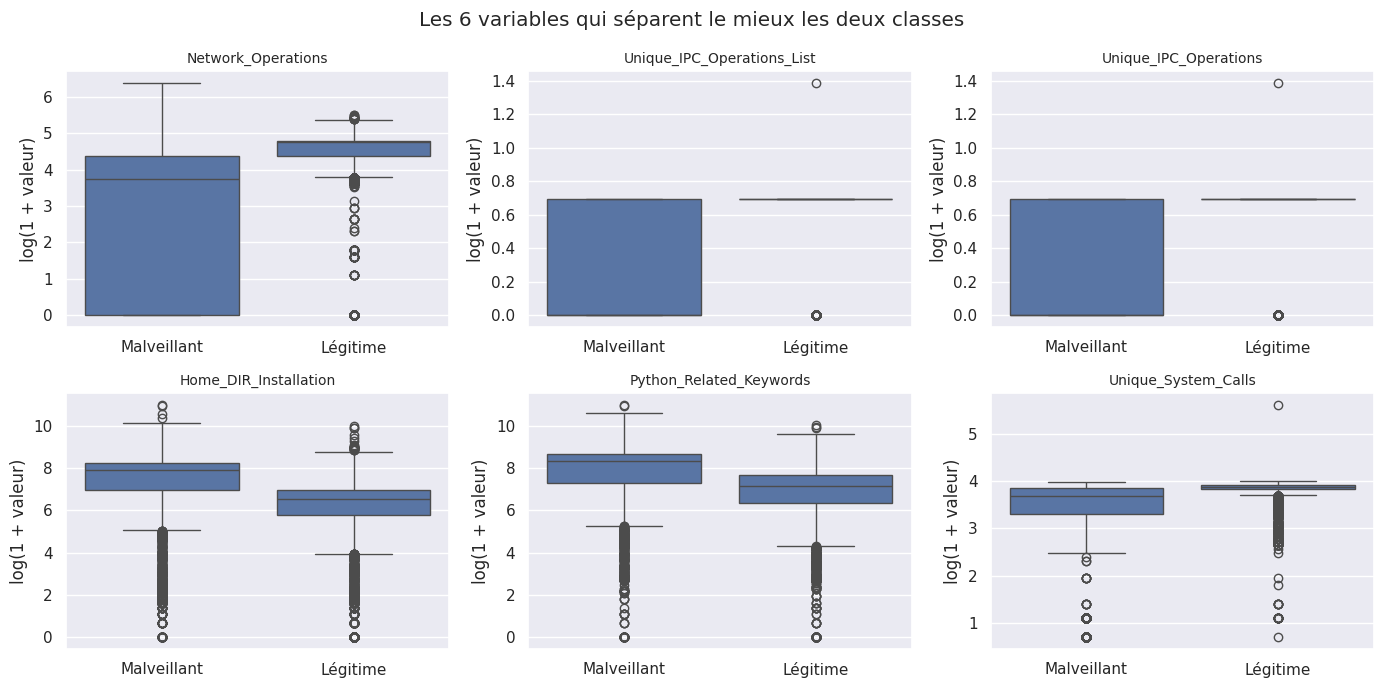

In [6]:
m0, m1 = X_num[y_all == 0].mean(), X_num[y_all == 1].mean()
cohen_d = ((m1 - m0) / X_num.std().replace(0, np.nan)).fillna(0)
pvals = {}
for c in FEATURE_COLS:
    a, b = X_num.loc[y_all == 0, c], X_num.loc[y_all == 1, c]
    pvals[c] = 1.0 if X_num[c].nunique() <= 1 else mannwhitneyu(a, b).pvalue

diff = pd.DataFrame({"famille": [group_of(c) for c in FEATURE_COLS], "moy_légitime": m0.values, "moy_malveillant": m1.values,
                     "d_Cohen": cohen_d.values, "p_MannWhitney": [pvals[c] for c in FEATURE_COLS]}, index=FEATURE_COLS)
diff = diff.reindex(diff["d_Cohen"].abs().sort_values(ascending=False).index)
display(diff.head(15).round(4))
print("Variables significativement différentes (p < 0,05) :", int((diff["p_MannWhitney"] < 0.05).sum()), "sur", len(diff))

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), diff.index[:6]):
    sns.boxplot(x=y_all.map({0: "Légitime", 1: "Malveillant"}), y=np.log1p(X_num[c]), ax=ax)
    ax.set_title(c, fontsize=10); ax.set_xlabel(""); ax.set_ylabel("log(1 + valeur)")
plt.suptitle("Les 6 variables qui séparent le mieux les deux classes"); plt.tight_layout(); plt.show()

## 4. Préparation des données
1. **Conversion** des colonnes textuelles en nombres (§2) ; valeurs manquantes = 0 (aucune activité observée).
2. **Doublons** : suppression des lignes au vecteur de variables identique, et des cas **contradictoires** (même vecteur, labels différents).
3. **Découpage 70 / 15 / 15** (train / validation / test), stratifié **par groupe de paquet** : les versions d'un même paquet (`pkg-1.0`, `pkg-1.1`) restent du même côté, sinon des traces quasi identiques fuiraient du train vers le test.
4. **Sélection des variables, calculée sur le train uniquement** : retrait des variables **constantes**, puis des variables **redondantes** (|r| ≥ 0,90 ; on garde celle qui a la plus forte information mutuelle avec le label).
5. **Pas de normalisation** : CatBoost et EBM (modèles à base d'arbres) n'en ont pas besoin.

In [7]:
# --- 1) doublons et contradictions ---
h = pd.util.hash_pandas_object(X_num, index=False)
conflict = pd.DataFrame({"h": h, "y": y_all}).groupby("h")["y"].nunique()
bad = h.isin(conflict[conflict > 1].index)
keep = ~bad & ~X_num.assign(_y=y_all.values).duplicated()
print(f"Lignes contradictoires retirées : {int(bad.sum())} | lignes avant : {len(X_num)} | après : {int(keep.sum())}")

X_all = X_num[keep].reset_index(drop=True)
y = y_all[keep].reset_index(drop=True)
base_name = raw.loc[keep, ID_COL].astype(str).str.replace(r"-\d[^-]*$", "", regex=True).reset_index(drop=True)
groups = pd.factorize(base_name)[0]
print("Paquets distincts (groupes) :", len(set(groups)))

# --- 2) découpage 70/15/15 stratifié par groupe ---
def split_groups(idx, n_splits):
    sg = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    rest, part = next(sg.split(np.zeros(len(idx)), y.iloc[idx], groups[idx]))
    return idx[rest], idx[part]

idx_rest, idx_test = split_groups(np.arange(len(y)), 7)    # ≈ 14 % test
idx_train, idx_val = split_groups(idx_rest, 6)             # ≈ 14 % validation
split_table = pd.DataFrame({"nb paquets": [len(idx_train), len(idx_val), len(idx_test)],
                            "% malveillants": [y.iloc[i].mean() * 100 for i in (idx_train, idx_val, idx_test)]},
                           index=["train", "validation", "test"]).round(1)
display(split_table)
assert not (set(groups[idx_train]) & set(groups[idx_test])), "fuite de groupes train/test"

Lignes contradictoires retirées : 0 | lignes avant : 14271 | après : 14223
Paquets distincts (groupes) : 13349


,nb paquets,% malveillants
train,10102,49.4
validation,2029,50.2
test,2092,51.1


In [8]:
# --- 3) sélection des variables (train uniquement) ---
Xtr_full, ytr = X_all.iloc[idx_train], y.iloc[idx_train]
mt0, mt1 = Xtr_full[ytr == 0].mean(), Xtr_full[ytr == 1].mean()
removed = {c: "Constante : aucune information" for c in FEATURE_COLS if Xtr_full[c].nunique() <= 1}

remaining = [c for c in FEATURE_COLS if c not in removed]
mi = pd.Series(mutual_info_classif(Xtr_full[remaining], ytr, random_state=SEED), index=remaining).sort_values(ascending=False)
corr = Xtr_full[remaining].corr().abs()
FEATURES = []
for c in mi.index:
    partner = next((k for k in FEATURES if corr.loc[c, k] >= 0.90), None)
    if partner is None: FEATURES.append(c)
    else: removed[c] = f"Redondante : |r| = {corr.loc[c, partner]:.2f} avec {partner}"

def why_kept(c):
    mesure, risque = FAMILY_INFO.get(group_of(c), ("comportement du paquet", "signal de comportement du paquet"))
    sens = "plus élevée" if mt1[c] > mt0[c] else "plus faible"
    return (f"Mesure : {mesure}. Intérêt sécurité : {risque}. Valeur moyenne {sens} chez les malveillants "
            f"({mt0[c]:.1f} légitime contre {mt1[c]:.1f} malveillant). Information mutuelle = {mi[c]:.3f} "
            f"(rang {list(mi.index).index(c) + 1}/{len(mi)}) ; non redondante (|r| < 0,90).")

feature_table = pd.DataFrame(
    [{"variable": c, "famille": group_of(c), "décision": "RETENUE", "info_mutuelle": round(mi[c], 4), "justification": why_kept(c)} for c in FEATURES] +
    [{"variable": c, "famille": group_of(c), "décision": "RETIRÉE", "info_mutuelle": round(mi[c], 4) if c in mi.index else np.nan,
      "justification": r} for c, r in removed.items()])
feature_table.to_csv("selection_variables.csv", index=False)
print(f"{len(FEATURES)} variables retenues sur {len(FEATURE_COLS)}")
display(feature_table[feature_table["décision"] == "RETENUE"].drop(columns="décision").reset_index(drop=True))
print("Variables retirées :")
display(feature_table[feature_table["décision"] == "RETIRÉE"][["variable", "famille", "justification"]].reset_index(drop=True))

X_train, y_train = X_all.iloc[idx_train][FEATURES], y.iloc[idx_train]
X_val,   y_val   = X_all.iloc[idx_val][FEATURES],   y.iloc[idx_val]
X_test,  y_test  = X_all.iloc[idx_test][FEATURES],  y.iloc[idx_test]

45 variables retenues sur 78


,variable,famille,info_mutuelle,justification
0,Network_Operations,SysCall,0.2954,Mesure : appels système par catégorie. Intérêt sécurité : beaucoup d'appels liés aux droits ou aux processus peut in...
1,Home_DIR_Installation,Opensnoop,0.2313,"Mesure : ouvertures de fichiers par zone du système. Intérêt sécurité : l'accès à des zones sensibles (/root, /etc, ..."
2,File_Operations,SysCall,0.2270,Mesure : appels système par catégorie. Intérêt sécurité : beaucoup d'appels liés aux droits ou aux processus peut in...
3,Root_DIR_Installation,Opensnoop,0.2235,"Mesure : ouvertures de fichiers par zone du système. Intérêt sécurité : l'accès à des zones sensibles (/root, /etc, ..."
4,Process_Management_Operations,SysCall,0.2211,Mesure : appels système par catégorie. Intérêt sécurité : beaucoup d'appels liés aux droits ou aux processus peut in...
5,Direct_Dependencies,Install,0.2169,Mesure : dépendances installées avec le paquet. Intérêt sécurité : un paquet peut introduire indirectement une dépen...
6,IO_Operations,SysCall,0.2006,Mesure : appels système par catégorie. Intérêt sécurité : beaucoup d'appels liés aux droits ou aux processus peut in...
7,Miscellaneous_Operations,SysCall,0.2002,Mesure : appels système par catégorie. Intérêt sécurité : beaucoup d'appels liés aux droits ou aux processus peut in...
8,IPC_Operations,SysCall,0.1908,Mesure : appels système par catégorie. Intérêt sécurité : beaucoup d'appels liés aux droits ou aux processus peut in...
9,Unique_System_Calls_List,SysCall,0.1743,Mesure : appels système par catégorie. Intérêt sécurité : beaucoup d'appels liés aux droits ou aux processus peut in...


Variables retirées :


,variable,famille,justification
0,Python_Related_Keywords,Opensnoop,Redondante : |r| = 0.96 avec Home_DIR_Installation
1,Direct_Dependency_Count,Install,Redondante : |r| = 0.97 avec Direct_Dependencies
2,Total_System_Calls,SysCall,Redondante : |r| = 0.99 avec File_Operations
3,Unique_System_Calls,SysCall,Redondante : |r| = 1.00 avec Unique_System_Calls_List
4,Unique_File_Operations,SysCall,Redondante : |r| = 1.00 avec Unique_File_Operations_List
5,Total_Dependency_Count,Install,Redondante : |r| = 1.00 avec Total_Dependencies
6,Unique_Process_Management_Operations,SysCall,Redondante : |r| = 1.00 avec Unique_Process_Management_Operations_List
7,Unique_IPC_Operations_List,SysCall,Redondante : |r| = 0.95 avec Unique_Process_Management_Operations_List
8,Unique_IPC_Operations,SysCall,Redondante : |r| = 0.95 avec Unique_Process_Management_Operations_List
9,Unique_Miscellaneous_Operations,SysCall,Redondante : |r| = 1.00 avec Unique_Miscellaneous_Operations_List


## 5. Modèle CatBoost
Boosting de 1000 arbres au maximum (profondeur 6, pas d'apprentissage 0,05) avec **arrêt anticipé** sur le jeu de validation (métrique AUC, patience 50).

In [9]:
CB_PARAMS = dict(iterations=1000, learning_rate=0.05, depth=6, loss_function="Logloss", eval_metric="AUC",
                 early_stopping_rounds=50, random_seed=SEED, verbose=0)
cb = CatBoostClassifier(**CB_PARAMS)
t0 = time.time()
cb.fit(X_train, y_train, eval_set=(X_val, y_val), use_best_model=True)
cb_fit_time = time.time() - t0
print(f"CatBoost entraîné en {cb_fit_time:.1f} s | meilleur nombre d'arbres : {cb.get_best_iteration() + 1}")
p_cb = cb.predict_proba(X_test)[:, 1]

CatBoost entraîné en 6.0 s | meilleur nombre d'arbres : 395


## 6. Modèle Explainable Boosting Machine
EBM est **interprétable par construction** : le score est une somme de fonctions de chaque variable, plus 5 interactions de 2 variables. L'EBM utilise sa propre validation interne (pas besoin du jeu de validation).

In [10]:
EBM_PARAMS = dict(interactions=5, max_bins=256, learning_rate=0.015, outer_bags=8, random_state=SEED, n_jobs=-1)
ebm = ExplainableBoostingClassifier(**EBM_PARAMS)
t0 = time.time()
ebm.fit(X_train, y_train)
ebm_fit_time = time.time() - t0
print(f"EBM entraîné en {ebm_fit_time:.1f} s | nombre de termes : {len(ebm.term_names_)}")
p_ebm = ebm.predict_proba(X_test)[:, 1]

EBM entraîné en 108.7 s | nombre de termes : 50


## 7. Classer les paquets selon leur niveau de risque
La probabilité d'être malveillant est découpée en 4 niveaux, chacun associé à une action. Le tableau vérifie la cohérence : le **taux réel de malveillants doit augmenter avec le niveau**.

| Probabilité | Niveau | Action |
|---|---|---|
| < 0,20 | Faible | Autoriser |
| 0,20 – 0,50 | Moyen | Revue manuelle |
| 0,50 – 0,80 | Élevé | Quarantaine |
| ≥ 0,80 | Critique | Bloquer |

In [11]:
RISK_BINS   = [0, 0.20, 0.50, 0.80, 1.0001]
RISK_LABELS = ["Faible", "Moyen", "Élevé", "Critique"]
ACTION = {"Faible": "Autoriser", "Moyen": "Revue manuelle", "Élevé": "Quarantaine", "Critique": "Bloquer"}

def risk_level(p):
    return pd.cut(pd.Series(p), bins=RISK_BINS, labels=RISK_LABELS, right=False, include_lowest=True)

risk_tables = {}
for name, p in [("CatBoost", p_cb), ("EBM", p_ebm)]:
    t = (pd.DataFrame({"risque": risk_level(p).values, "y": y_test.values})
           .groupby("risque", observed=False)["y"].agg(nb_paquets="count", nb_malveillants="sum", taux_malveillants_reel="mean")
           .reindex(RISK_LABELS))
    t["action"] = [ACTION[r] for r in t.index]
    risk_tables[name] = t
    print(f"\n=== {name} ==="); display(t.round(3))


=== CatBoost ===


,nb_paquets,nb_malveillants,taux_malveillants_reel,action
risque,,,,
Faible,1006,1,0.001,Autoriser
Moyen,12,5,0.417,Revue manuelle
Élevé,15,8,0.533,Quarantaine
Critique,1059,1056,0.997,Bloquer



=== EBM ===


,nb_paquets,nb_malveillants,taux_malveillants_reel,action
risque,,,,
Faible,1014,5,0.005,Autoriser
Moyen,10,3,0.300,Revue manuelle
Élevé,9,6,0.667,Quarantaine
Critique,1059,1056,0.997,Bloquer


## 8. Comparaison des performances
Seuil de décision 0,5, jeu de test. **FPR** = légitimes bloqués à tort ; **FNR** = malveillants non détectés (le plus dangereux en sécurité). **MCC** et **PR-AUC** résument la qualité globale même en cas de déséquilibre.

,Accuracy,Précision,Rappel (TPR),F1,ROC-AUC,PR-AUC,MCC,FPR,FNR,VP,FP,VN,FN,Temps entraînement (s)
Modèle,,,,,,,,,,,,,,
CatBoost,0.9924,0.9907,0.9944,0.9925,0.9998,0.9998,0.9847,0.0098,0.0056,1064,10,1012,6,6.0253
EBM,0.9933,0.9944,0.9925,0.9935,0.9998,0.9998,0.9866,0.0059,0.0075,1062,6,1016,8,108.6968


,Modèle,Paramètres,Données
0,CatBoost,"{'iterations': 1000, 'learning_rate': 0.05, 'depth': 6, 'loss_function': 'Logloss', 'eval_metric': 'AUC', 'early_sto...","train=10102, validation=2029 (arrêt anticipé), test=2092"
1,EBM,"{'interactions': 5, 'max_bins': 256, 'learning_rate': 0.015, 'outer_bags': 8, 'random_state': 42, 'n_jobs': -1}","train=10102 (validation interne EBM), test=2092"


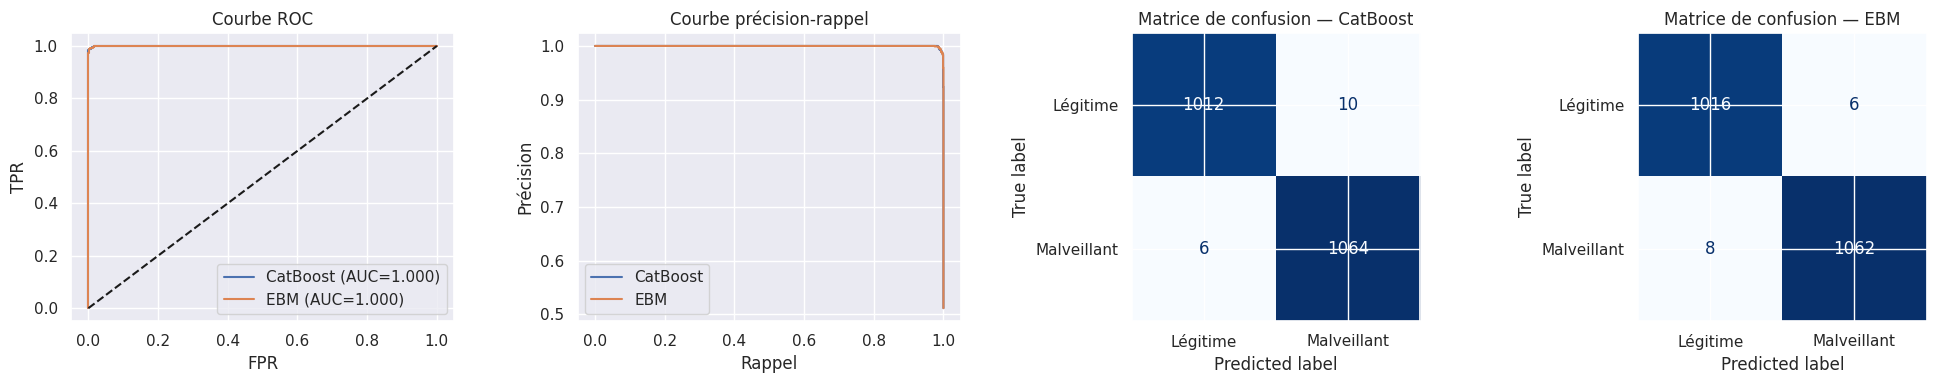

In [12]:
def evaluate(name, y_true, p, fit_time, thr=0.5):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {"Modèle": name, "Accuracy": accuracy_score(y_true, pred), "Précision": precision_score(y_true, pred),
            "Rappel (TPR)": recall_score(y_true, pred), "F1": f1_score(y_true, pred),
            "ROC-AUC": roc_auc_score(y_true, p), "PR-AUC": average_precision_score(y_true, p),
            "MCC": matthews_corrcoef(y_true, pred), "FPR": fp / (fp + tn), "FNR": fn / (fn + tp),
            "VP": tp, "FP": fp, "VN": tn, "FN": fn, "Temps entraînement (s)": fit_time}

results = pd.DataFrame([evaluate("CatBoost", y_test, p_cb, cb_fit_time),
                        evaluate("EBM", y_test, p_ebm, ebm_fit_time)]).set_index("Modèle")
display(results.round(4)); results.round(4).to_csv("resultats_modeles.csv")

params_table = pd.DataFrame({"Modèle": ["CatBoost", "EBM"], "Paramètres": [str(CB_PARAMS), str(EBM_PARAMS)],
                             "Données": [f"train={len(X_train)}, validation={len(X_val)} (arrêt anticipé), test={len(X_test)}",
                                         f"train={len(X_train)} (validation interne EBM), test={len(X_test)}"]})
display(params_table); params_table.to_csv("parametres_modeles.csv", index=False)

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for name, p in [("CatBoost", p_cb), ("EBM", p_ebm)]:
    fpr, tpr, _ = roc_curve(y_test, p); axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p); axes[1].plot(rc, pr, label=name)
axes[0].plot([0, 1], [0, 1], "k--"); axes[0].set(title="Courbe ROC", xlabel="FPR", ylabel="TPR"); axes[0].legend()
axes[1].set(title="Courbe précision-rappel", xlabel="Rappel", ylabel="Précision"); axes[1].legend()
for ax, (name, p) in zip(axes[2:], [("CatBoost", p_cb), ("EBM", p_ebm)]):
    ConfusionMatrixDisplay.from_predictions(y_test, (p >= 0.5).astype(int), display_labels=["Légitime", "Malveillant"],
                                            cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"Matrice de confusion — {name}")
plt.tight_layout(); plt.savefig("fig_performance.png", dpi=120, bbox_inches="tight"); plt.show()

## 9. Caractéristiques les plus influentes
Trois points de vue : importance native de CatBoost, importance native d'EBM (variables **et** interactions), et importance **par permutation** (baisse de ROC-AUC sur le test) commune aux deux modèles.

,famille,CatBoost (native),EBM (native),CatBoost (permutation),EBM (permutation)
Direct_Dependencies,Install,0.2470,0.1547,0.0601,0.1047
Total_Dependencies,Install,0.1153,0.0763,0.0038,0.0043
Unique_File_Operations_List,SysCall,0.0624,0.0385,0.0010,0.0048
Network_Operations,SysCall,0.0544,0.0279,0.0007,0.0004
Home_DIR_Installation,Opensnoop,0.0501,0.0204,0.0002,-0.0000
Miscellaneous_Operations,SysCall,0.0368,0.0420,0.0005,0.0009
File_Operations,SysCall,0.0359,0.0297,0.0002,0.0005
IO_Operations,SysCall,0.0347,0.0217,0.0001,0.0003
Unique_Memory_Operations_List,SysCall,0.0312,0.0388,0.0004,0.0004
Total_Write_Data_Transfer,Filetop,0.0246,0.0172,0.0001,0.0001


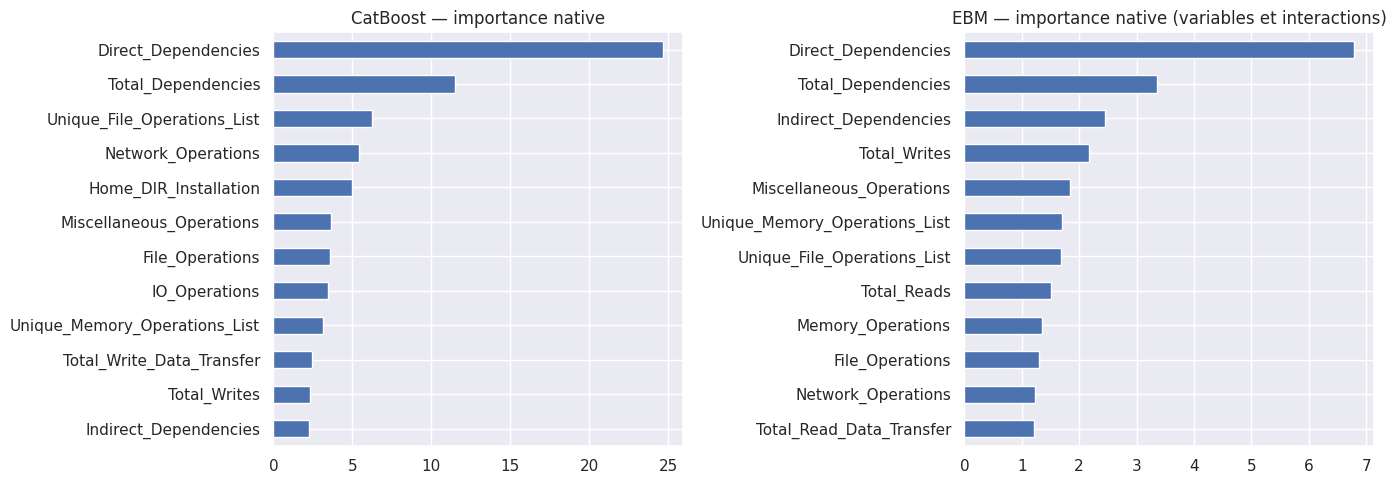

Top 5 CatBoost : ['Direct_Dependencies', 'Total_Dependencies', 'Unique_File_Operations_List', 'Network_Operations', 'Home_DIR_Installation']
Top 5 EBM      : ['Direct_Dependencies', 'Total_Dependencies', 'Indirect_Dependencies', 'Total_Writes', 'Miscellaneous_Operations']


In [13]:
imp_cb  = pd.Series(cb.get_feature_importance(), index=FEATURES)
imp_ebm = pd.Series(ebm.term_importances(), index=ebm.term_names_)
perm_cb  = permutation_importance(cb,  X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=SEED, n_jobs=-1)
perm_ebm = permutation_importance(ebm, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=SEED)

imp = pd.DataFrame({"famille": [group_of(c) for c in FEATURES],
                    "CatBoost (native)": (imp_cb / imp_cb.sum()).values,
                    "EBM (native)": (imp_ebm / imp_ebm.sum()).reindex(FEATURES).values,
                    "CatBoost (permutation)": perm_cb.importances_mean,
                    "EBM (permutation)": perm_ebm.importances_mean}, index=FEATURES)
imp = imp.sort_values("CatBoost (native)", ascending=False)
display(imp.head(15).round(4)); imp.round(5).to_csv("importance_variables.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
imp_cb.sort_values().tail(12).plot.barh(ax=axes[0], title="CatBoost — importance native")
imp_ebm.sort_values().tail(12).plot.barh(ax=axes[1], title="EBM — importance native (variables et interactions)")
plt.tight_layout(); plt.savefig("fig_importance.png", dpi=120, bbox_inches="tight"); plt.show()

top_cb, top_ebm = list(imp_cb.sort_values(ascending=False).index[:5]), list(imp_ebm.sort_values(ascending=False).index[:5])
print("Top 5 CatBoost :", top_cb); print("Top 5 EBM      :", top_ebm)

## 10. Explication de chaque décision du modèle
- **EBM** : contribution exacte de chaque terme au score (`eval_terms`).
- **CatBoost** : valeurs **SHAP** natives.

Une contribution **positive** pousse vers « malveillant », une négative vers « légitime ». Le fichier `explications_test.csv` donne, pour **chaque paquet du test**, la probabilité, le niveau de risque et les 3 raisons principales.

Explications produites pour 2092 paquets du jeu de test


,package,vrai_label,proba_CatBoost,risque_CatBoost,raisons_CatBoost,proba_EBM,risque_EBM,raisons_EBM
0,11Cent-999.0.0.tar.gz,1,0.9427,Critique,Direct_Dependencies (+1.43); Home_DIR_Installation (+0.98); Total_Dependencies (-0.86),0.9967,Critique,Direct_Dependencies (+4.56); Total_Dependencies (-2.97); Unique_Memory_Operations_List (+1.65)
1,11Cent-999.0.1.tar.gz,1,0.8230,Critique,Total_Dependencies (-1.13); Direct_Dependencies (+1.04); Unique_File_Operations_List (+0.77),0.9122,Critique,Direct_Dependencies (+4.56); Total_Dependencies (-2.97); Memory_Operations (-2.60)
2,11Cent-999.0.2.tar.gz,1,0.9951,Critique,Unique_File_Operations_List (+1.39); Direct_Dependencies (+0.97); Total_Dependencies (-0.93),0.9995,Critique,Direct_Dependencies (+4.56); Unique_File_Operations_List (+3.59); Total_Dependencies (-2.97)
3,11Cent-999.0.3.tar.gz,1,0.9021,Critique,Direct_Dependencies (+1.82); File_Operations (+0.88); IO_Operations (+0.88),0.9985,Critique,Direct_Dependencies (+4.56); Total_Dependencies (-2.97); File_Operations (+2.20)
4,11Cent-999.0.4.tar.gz,1,0.9725,Critique,Direct_Dependencies (+1.34); Total_Dependencies (-0.98); Network_Operations (+0.94),0.9991,Critique,Direct_Dependencies (+4.56); Total_Dependencies (-2.97); Total_Writes (+2.08)
5,1337x,0,0.0001,Faible,Direct_Dependencies (-3.56); Network_Operations (-0.89); Unique_File_Operations_List (-0.79),0.0000,Faible,Direct_Dependencies (-12.88); Indirect_Dependencies (+6.09); Remote_Port_Access (-5.47)
6,2022-requests-3.0.0.tar.gz,1,0.9949,Critique,Direct_Dependencies (+3.28); Total_Dependencies (+1.29); Total_Writes (+0.81),1.0000,Critique,Indirect_Dependencies (+4.73); Direct_Dependencies (+4.56); Total_Writes (+4.14)
7,5345345345345345,0,0.0016,Faible,Direct_Dependencies (+1.31); Network_Operations (-1.27); Unique_File_Operations_List (-1.21),0.0000,Faible,Remote_Port_Access (-5.12); Direct_Dependencies (+4.56); Total_Writes (+4.15)


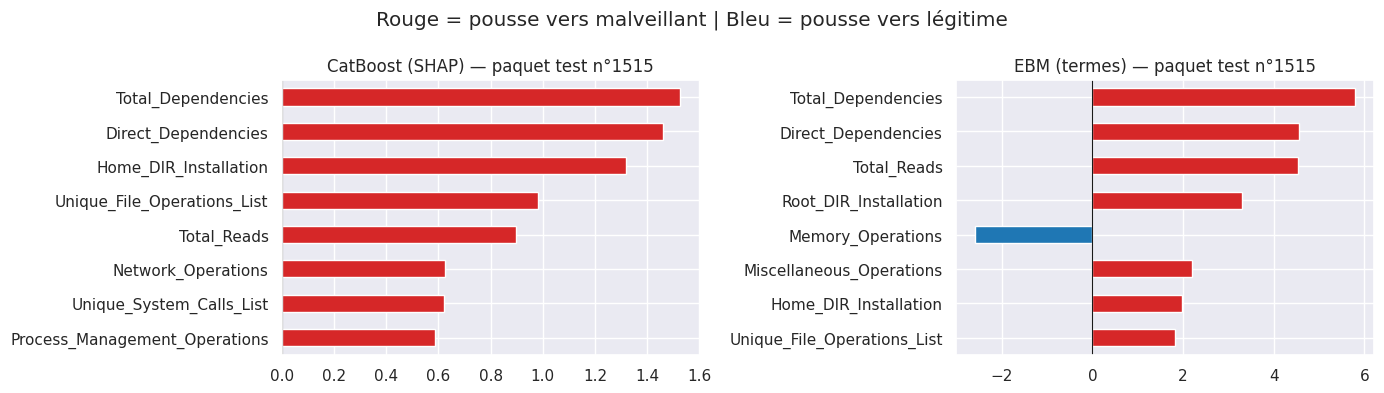

In [14]:
shap_cb = cb.get_feature_importance(Pool(X_test, y_test), type="ShapValues")[:, :-1]
contrib_cb  = pd.DataFrame(shap_cb, columns=FEATURES)
contrib_ebm = pd.DataFrame(ebm.eval_terms(X_test), columns=ebm.term_names_)

def top_reasons(row, k=3):
    s = row.reindex(row.abs().sort_values(ascending=False).index)[:k]
    return "; ".join(f"{n} ({v:+.2f})" for n, v in s.items())

explications = pd.DataFrame({
    "package": raw.loc[keep, ID_COL].reset_index(drop=True).iloc[idx_test].values,
    "vrai_label": y_test.values,
    "proba_CatBoost": p_cb.round(4), "risque_CatBoost": risk_level(p_cb).values,
    "raisons_CatBoost": contrib_cb.apply(top_reasons, axis=1).values,
    "proba_EBM": p_ebm.round(4), "risque_EBM": risk_level(p_ebm).values,
    "raisons_EBM": contrib_ebm.apply(top_reasons, axis=1).values})
explications.to_csv("explications_test.csv", index=False)
print("Explications produites pour", len(explications), "paquets du jeu de test")
display(explications.head(8))

# Exemple visuel : malveillant détecté avec la plus forte confiance (moyenne des deux modèles)
conf = pd.Series((p_cb + p_ebm) / 2)
ex = int(conf[y_test.values == 1].idxmax())
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (n, c) in zip(axes, [("CatBoost (SHAP)", contrib_cb), ("EBM (termes)", contrib_ebm)]):
    r = c.iloc[ex]; r = r.reindex(r.abs().sort_values().index)[-8:]
    r.plot.barh(ax=ax, color=["tab:red" if v > 0 else "tab:blue" for v in r.values])
    ax.set_title(f"{n} — paquet test n°{ex}"); ax.axvline(0, color="k", lw=0.8)
plt.suptitle("Rouge = pousse vers malveillant | Bleu = pousse vers légitime"); plt.tight_layout(); plt.show()

## 11. Étude des erreurs de classification (Tâche 11)
Types de résultats (VP, VN, **FP** = légitime bloqué, **FN** = malveillant manqué), erreurs communes aux deux modèles, profil moyen des paquets mal classés et erreurs les plus « confiantes » avec leur explication.

,CatBoost,EBM
VP,1064,1062
VN,1012,1016
FP,10,6
FN,6,8


Erreurs communes aux deux modèles : 8 | seulement CatBoost : 8 | seulement EBM : 6


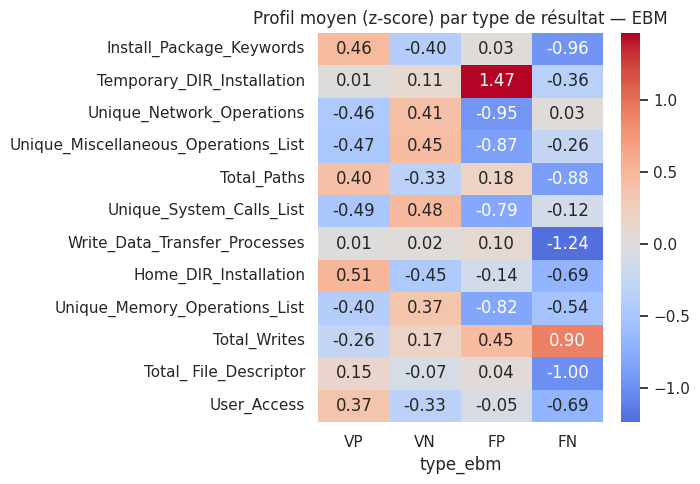

,type,vrai,p_EBM,raisons_EBM
0,FN,1,0.013,Indirect_Dependencies (+6.77); Total_Writes (-5.41); Direct_Dependencies (+4.56)
1,FP,0,0.957,Total_Writes (-5.41); Indirect_Dependencies (+4.75); Direct_Dependencies (+4.56)
2,FN,1,0.066,Direct_Dependencies (+4.56); Miscellaneous_Operations (-3.21); Total_Dependencies (-2.97)
3,FP,0,0.899,Total_Writes (-5.17); Direct_Dependencies (+4.56); Total_Dependencies (-2.97)
4,FN,1,0.106,Direct_Dependencies (+4.56); Total_Writes (+4.15); Total_Dependencies (-2.97)


In [15]:
res = pd.DataFrame({"y": y_test.values, "p_cb": p_cb, "p_ebm": p_ebm}, index=X_test.index)
for m in ["cb", "ebm"]:
    res[f"pred_{m}"] = (res[f"p_{m}"] >= 0.5).astype(int)
    res[f"type_{m}"] = np.select([(res.y == 1) & (res[f"pred_{m}"] == 1), (res.y == 0) & (res[f"pred_{m}"] == 0),
                                  (res.y == 0) & (res[f"pred_{m}"] == 1)], ["VP", "VN", "FP"], "FN")
display(pd.concat([res["type_cb"].value_counts().rename("CatBoost"), res["type_ebm"].value_counts().rename("EBM")], axis=1).fillna(0).astype(int))

err_cb, err_ebm = res.type_cb.isin(["FP", "FN"]), res.type_ebm.isin(["FP", "FN"])
print("Erreurs communes aux deux modèles :", int((err_cb & err_ebm).sum()),
      "| seulement CatBoost :", int((err_cb & ~err_ebm).sum()), "| seulement EBM :", int((~err_cb & err_ebm).sum()))

# Profil moyen (z-score) par type de résultat (EBM)
z = (X_test - X_train.mean()) / X_train.std().replace(0, np.nan)
prof = z.groupby(res["type_ebm"]).mean().T
cols_show = [c for c in ["VP", "VN", "FP", "FN"] if c in prof.columns]
gap = pd.concat([(prof["FN"] - prof["VP"]).abs() if {"FN", "VP"} <= set(prof.columns) else None,
                 (prof["FP"] - prof["VN"]).abs() if {"FP", "VN"} <= set(prof.columns) else None], axis=1).max(axis=1)
top_err = prof.loc[gap.sort_values(ascending=False).index[:12], cols_show]
plt.figure(figsize=(7, 5)); sns.heatmap(top_err, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Profil moyen (z-score) par type de résultat — EBM"); plt.tight_layout(); plt.show()

# Erreurs les plus confiantes (EBM) avec explication
errors_conf = res[err_ebm].assign(conf=lambda d: (d.p_ebm - 0.5).abs()).sort_values("conf", ascending=False).head(5)
pos = [res.index.get_loc(i) for i in errors_conf.index]
display(pd.DataFrame({"type": errors_conf.type_ebm.values, "vrai": errors_conf.y.values, "p_EBM": errors_conf.p_ebm.round(3).values,
                      "raisons_EBM": explications.iloc[pos]["raisons_EBM"].values}))
res.to_csv("erreurs_test.csv")

## 12. Stratégie d'intégration dans une chaîne CI/CD sécurisée (Tâche 12)
Sauvegarde des modèles (avec empreinte SHA-256 pour vérifier leur intégrité) et fonction de décision réutilisable dans un pipeline.

In [16]:
import joblib
cb.save_model("qutdv25_catboost.cbm")
joblib.dump(ebm, "qutdv25_ebm.joblib")
sha256 = lambda p: hashlib.sha256(Path(p).read_bytes()).hexdigest()
json.dump({"features": FEATURES, "risk_bins": RISK_BINS, "risk_labels": RISK_LABELS, "action": ACTION, "versions": ENV,
           "sha256": {f: sha256(f) for f in ["qutdv25_catboost.cbm", "qutdv25_ebm.joblib"]}},
          open("qutdv25_config.json", "w"), indent=2, ensure_ascii=False)

def decide(features: dict, cb_model=cb, ebm_model=ebm):
    """Entrée : variables eBPF d'un paquet (dict). Sortie : probabilités, niveau de risque, action CI/CD."""
    x = pd.DataFrame([features])[FEATURES]
    p1, p2 = float(cb_model.predict_proba(x)[0, 1]), float(ebm_model.predict_proba(x)[0, 1])
    level = str(risk_level([max(p1, p2)]).iloc[0])        # précaution : on garde le score le plus élevé
    return {"p_catboost": round(p1, 3), "p_ebm": round(p2, 3), "risque": level, "action": ACTION[level]}

print(decide(X_test.iloc[0].to_dict()))

{'p_catboost': 0.943, 'p_ebm': 0.997, 'risque': 'Critique', 'action': 'Bloquer'}


### Pipeline proposé

```
Commit / nouvelle dépendance
        │
        ▼
[1] Résolution + épinglage des versions (lockfile, hashes)            ← bloque si hash inconnu
        │
        ▼
[2] Bac à sable isolé, sans secrets (eBPF : installation + 120 s)      ← produit les variables
        │
        ▼
[3] Scoring : CatBoost (score) + EBM (explication)  → niveau de risque
        │
   ┌────┴─────────────┬───────────────┬──────────────┐
 Faible            Moyen            Élevé         Critique
 Autoriser     Revue manuelle     Quarantaine      Bloquer
        │            │                │              │
        └────────────┴────────┬───────┴──────────────┘
                              ▼
[4] Journal d'audit signé : paquet, version, score, 3 raisons, décision
                              ▼
[5] Boucle de rétroaction : décisions humaines + nouveaux paquets → réentraînement planifié
```

**Mesures de sécurité de la chaîne**
- **Intégrité des modèles** : artefacts (`.cbm`, `.joblib`) signés ; empreinte SHA-256 (`qutdv25_config.json`) vérifiée avant chargement ; ne jamais charger un `.joblib` non signé (désérialisation = exécution de code).
- **Reproductibilité** : versions des bibliothèques et `random_state` figés ; modèle versionné avec ses métriques.
- **Isolation** : l'analyse dynamique s'exécute uniquement dans un bac à sable jetable, jamais sur le runner de build.
- **Seuils orientés risque** : le FNR (malveillants manqués) coûte plus cher que le FPR ; abaisser le seuil de « Moyen » pour détecter davantage, au prix de revues manuelles.
- **Explicabilité** : chaque décision archive ses 3 raisons principales pour l'audit et la contestation.
- **Surveillance de dérive** : suivre la distribution des variables et la part de paquets « Élevé/Critique » ; alerter en cas de dérive.
- **Robustesse** : évasions possibles (activation après 120 s, détection du bac à sable) → le modèle n'est jamais la seule barrière ; le combiner avec liste de blocage, vérification de signatures et analyse statique.
- **Moindre privilège** : le job CI n'a que les droits nécessaires ; les secrets sont inaccessibles à l'étape de bac à sable.

**Extrait d'étape CI (GitHub Actions)**
```yaml
- name: Scan des dépendances (QUT-DV25)
  run: |
    python sandbox_trace.py --lockfile requirements.lock --out traces.csv
    python score_packages.py --traces traces.csv --model qutdv25_catboost.cbm \
                             --config qutdv25_config.json --fail-on "Élevé,Critique"
```

## 13. Rapport : variables, environnement, résultats et analyse
La cellule suivante rédige l'**analyse à partir de vos chiffres**, l'affiche, puis génère le document Word `Cas_QUT_DV25_rapport.docx` avec les 4 parties demandées : (1) variables retenues et justification, (2) environnement et paramètres, (3) résultats expérimentaux, (4) analyse, interprétation et comparaison.

In [17]:
r = results
best_f1 = r["F1"].idxmax(); other = [m for m in r.index if m != best_f1][0]
d_f1 = r.loc[best_f1, "F1"] - r.loc[other, "F1"]
best_auc, best_fnr, best_fpr = r["ROC-AUC"].idxmax(), r["FNR"].idxmin(), r["FPR"].idxmin()
slow, fast = r["Temps entraînement (s)"].idxmax(), r["Temps entraînement (s)"].idxmin()
ratio_t = r.loc[slow, "Temps entraînement (s)"] / max(r.loc[fast, "Temps entraînement (s)"], 1e-9)

common = [v for v in top_cb if v in top_ebm]
fam_top = pd.Series([group_of(v.split(" & ")[0]) for v in top_cb + top_ebm]).value_counts()
err_cb_n, err_ebm_n, both_n = int(err_cb.sum()), int(err_ebm.sum()), int((err_cb & err_ebm).sum())
mono = {m: t["taux_malveillants_reel"].dropna().is_monotonic_increasing for m, t in risk_tables.items()}
close = d_f1 < 0.01

analyse = [
 ("Comparaison des performances",
  f"Sur le jeu de test ({len(y_test)} paquets), {best_f1} obtient le meilleur F1 ({r.loc[best_f1,'F1']:.4f}) contre {r.loc[other,'F1']:.4f} "
  f"pour {other} (écart : {100*d_f1:.2f} point). Le meilleur ROC-AUC est celui de {best_auc} ({r.loc[best_auc,'ROC-AUC']:.4f}). " +
  ("L'écart est faible : les deux modèles sont équivalents en pratique, et un seul découpage train/test ne permet pas d'affirmer qu'il est significatif."
   if close else f"L'écart est notable en faveur de {best_f1}.")),
 ("Erreurs de sécurité (FNR et FPR)",
  f"Le taux de malveillants non détectés (FNR) est le plus faible pour {best_fnr} ({r.loc[best_fnr,'FNR']:.4f}) ; "
  f"le taux de légitimes bloqués à tort (FPR) est le plus faible pour {best_fpr} ({r.loc[best_fpr,'FPR']:.4f}). "
  "En sécurité, le FNR est le plus coûteux : un paquet malveillant non détecté entre dans la chaîne d'approvisionnement."),
 ("Compromis performance / interprétabilité",
  "CatBoost est une « boîte noire » expliquée a posteriori (SHAP) ; l'EBM est transparent : chaque décision est une somme exacte de contributions. " +
  ("Comme l'écart de performance est faible, l'EBM offre l'explicabilité presque sans perte de performance, ce qui le rend préférable pour l'audit."
   if close else "L'écart de performance indique un coût de l'interprétabilité ; le choix dépend du besoin (détection maximale ou justification des décisions).") +
  f" Temps d'entraînement : {slow} est environ {ratio_t:.1f} fois plus lent que {fast}."),
 ("Variables influentes",
  f"Top 5 CatBoost : {', '.join(top_cb)}. Top 5 EBM : {', '.join(top_ebm)}. Variables communes : {', '.join(common) if common else 'aucune'}. "
  f"Familles les plus représentées : {', '.join(f'{k} ({v})' for k, v in fam_top.items())}. "
  "Interprétation sécurité : voir les justifications de la §4."),
 ("Niveaux de risque",
  "Taux réel de malveillants — " + " ; ".join(f"{m} : " + ("croît avec le niveau de risque (classement cohérent)" if ok
                                                         else "ne croît pas strictement avec le niveau (à examiner)") for m, ok in mono.items()) +
  ". Les paquets de niveau « Moyen » sont envoyés en revue manuelle."),
 ("Étude des erreurs",
  f"CatBoost fait {err_cb_n} erreur(s) et EBM {err_ebm_n} sur {len(y_test)} paquets ; {both_n} sont communes aux deux modèles "
  "(paquets ambigus dont le comportement ressemble à celui de la classe opposée). Profils et explications : voir §11."),
 ("Limites",
  "Classes équilibrées dans le dataset alors que les paquets malveillants sont très minoritaires sur PyPI (les fausses alertes seraient bien plus nombreuses en production) ; "
  "trace limitée à 120 s (un malware qui s'active plus tard échappe à la mesure) ; un seul découpage train/validation/test ; PyPI uniquement."),
]
for titre, texte in analyse: print(f"■ {titre}\n{texte}\n")

■ Comparaison des performances
Sur le jeu de test (2092 paquets), EBM obtient le meilleur F1 (0.9935) contre 0.9925 pour CatBoost (écart : 0.09 point). Le meilleur ROC-AUC est celui de EBM (0.9998). L'écart est faible : les deux modèles sont équivalents en pratique, et un seul découpage train/test ne permet pas d'affirmer qu'il est significatif.

■ Erreurs de sécurité (FNR et FPR)
Le taux de malveillants non détectés (FNR) est le plus faible pour CatBoost (0.0056) ; le taux de légitimes bloqués à tort (FPR) est le plus faible pour EBM (0.0059). En sécurité, le FNR est le plus coûteux : un paquet malveillant non détecté entre dans la chaîne d'approvisionnement.

■ Compromis performance / interprétabilité
CatBoost est une « boîte noire » expliquée a posteriori (SHAP) ; l'EBM est transparent : chaque décision est une somme exacte de contributions. Comme l'écart de performance est faible, l'EBM offre l'explicabilité presque sans perte de performance, ce qui le rend préférable pour l'audit.

## 13. Rapport structuré (affiché dans le notebook)
Les 4 parties demandées sont générées ci-dessous **à partir de vos résultats**. Relisez et complétez l'analyse avec vos observations.

In [18]:
from IPython.display import Markdown

def show_md(text): display(Markdown(text))

# ---------- Partie 1 : variables retenues et justification ----------
show_md("# Partie 1 — Variables retenues et justification")
show_md(f"Sélection faite sur le **train uniquement** : retrait de l'identifiant, des variables constantes et des variables redondantes "
        f"(|r| ≥ 0,90, on garde celle qui a la plus forte information mutuelle). **{len(FEATURES)} variables retenues sur {len(FEATURE_COLS)}.** "
        f"Familles représentées : " + ", ".join(f"{k} ({v})" for k, v in pd.Series([group_of(c) for c in FEATURES]).value_counts().items()) + ".")
display(feature_table[feature_table["décision"] == "RETENUE"][["variable", "famille", "info_mutuelle", "justification"]].reset_index(drop=True))
show_md("**Variables retirées :**")
display(feature_table[feature_table["décision"] == "RETIRÉE"][["variable", "famille", "justification"]].reset_index(drop=True))

# ---------- Partie 2 : environnement et paramètres ----------
show_md("# Partie 2 — Environnement expérimental et paramètres")
display(pd.Series(ENV, name="valeur").to_frame())
show_md(f"**Données :** {len(X_all)} paquets après nettoyage, découpage ≈ 70/15/15 stratifié par groupe de paquet "
        f"(train {len(X_train)} / validation {len(X_val)} / test {len(X_test)}). Doublons et lignes contradictoires retirés avant le découpage ; pas de normalisation.")
display(params_table)

# ---------- Partie 3 : résultats ----------
show_md("# Partie 3 — Résultats expérimentaux (jeu de test, seuil 0,5)")
display(results.round(4))
show_md("**Niveaux de risque**")
for m, t in risk_tables.items():
    show_md(f"*{m}*"); display(t.round(3))
show_md("**Variables les plus influentes (top 10)**")
display(imp.head(10).round(4))

# ---------- Partie 4 : analyse ----------
show_md("# Partie 4 — Analyse, interprétation et comparaison")
for titre, texte in analyse:
    show_md(f"### {titre}\n{texte}")
show_md("### Conclusion\n" + f"**{best_f1}** est le meilleur modèle selon le F1. " +
        ("L'EBM reste recommandé pour l'audit grâce à son explicabilité exacte. " if close else "Le choix final dépend du compromis entre détection et explicabilité. ") +
        "Intégration CI/CD : analyse en bac à sable, score des deux modèles, décision selon le niveau de risque (voir §12), journal d'audit, modèles signés, surveillance de dérive.")

# Partie 1 — Variables retenues et justification

Sélection faite sur le **train uniquement** : retrait de l'identifiant, des variables constantes et des variables redondantes (|r| ≥ 0,90, on garde celle qui a la plus forte information mutuelle). **45 variables retenues sur 78.** Familles représentées : SysCall (19), Opensnoop (9), TCP (7), Filetop (5), Install (3), Pattern (2).

,variable,famille,info_mutuelle,justification
0,Network_Operations,SysCall,0.2954,Mesure : appels système par catégorie. Intérêt sécurité : beaucoup d'appels liés aux droits ou aux processus peut in...
1,Home_DIR_Installation,Opensnoop,0.2313,"Mesure : ouvertures de fichiers par zone du système. Intérêt sécurité : l'accès à des zones sensibles (/root, /etc, ..."
2,File_Operations,SysCall,0.2270,Mesure : appels système par catégorie. Intérêt sécurité : beaucoup d'appels liés aux droits ou aux processus peut in...
3,Root_DIR_Installation,Opensnoop,0.2235,"Mesure : ouvertures de fichiers par zone du système. Intérêt sécurité : l'accès à des zones sensibles (/root, /etc, ..."
4,Process_Management_Operations,SysCall,0.2211,Mesure : appels système par catégorie. Intérêt sécurité : beaucoup d'appels liés aux droits ou aux processus peut in...
5,Direct_Dependencies,Install,0.2169,Mesure : dépendances installées avec le paquet. Intérêt sécurité : un paquet peut introduire indirectement une dépen...
6,IO_Operations,SysCall,0.2006,Mesure : appels système par catégorie. Intérêt sécurité : beaucoup d'appels liés aux droits ou aux processus peut in...
7,Miscellaneous_Operations,SysCall,0.2002,Mesure : appels système par catégorie. Intérêt sécurité : beaucoup d'appels liés aux droits ou aux processus peut in...
8,IPC_Operations,SysCall,0.1908,Mesure : appels système par catégorie. Intérêt sécurité : beaucoup d'appels liés aux droits ou aux processus peut in...
9,Unique_System_Calls_List,SysCall,0.1743,Mesure : appels système par catégorie. Intérêt sécurité : beaucoup d'appels liés aux droits ou aux processus peut in...


**Variables retirées :**

,variable,famille,justification
0,Python_Related_Keywords,Opensnoop,Redondante : |r| = 0.96 avec Home_DIR_Installation
1,Direct_Dependency_Count,Install,Redondante : |r| = 0.97 avec Direct_Dependencies
2,Total_System_Calls,SysCall,Redondante : |r| = 0.99 avec File_Operations
3,Unique_System_Calls,SysCall,Redondante : |r| = 1.00 avec Unique_System_Calls_List
4,Unique_File_Operations,SysCall,Redondante : |r| = 1.00 avec Unique_File_Operations_List
5,Total_Dependency_Count,Install,Redondante : |r| = 1.00 avec Total_Dependencies
6,Unique_Process_Management_Operations,SysCall,Redondante : |r| = 1.00 avec Unique_Process_Management_Operations_List
7,Unique_IPC_Operations_List,SysCall,Redondante : |r| = 0.95 avec Unique_Process_Management_Operations_List
8,Unique_IPC_Operations,SysCall,Redondante : |r| = 0.95 avec Unique_Process_Management_Operations_List
9,Unique_Miscellaneous_Operations,SysCall,Redondante : |r| = 1.00 avec Unique_Miscellaneous_Operations_List


# Partie 2 — Environnement expérimental et paramètres

... (17 outputs left out)

### Niveaux de risque
Taux réel de malveillants — CatBoost : croît avec le niveau de risque (classement cohérent) ; EBM : croît avec le niveau de risque (classement cohérent). Les paquets de niveau « Moyen » sont envoyés en revue manuelle.

### Étude des erreurs
CatBoost fait 16 erreur(s) et EBM 14 sur 2092 paquets ; 8 sont communes aux deux modèles (paquets ambigus dont le comportement ressemble à celui de la classe opposée). Profils et explications : voir §11.

### Limites
Classes équilibrées dans le dataset alors que les paquets malveillants sont très minoritaires sur PyPI (les fausses alertes seraient bien plus nombreuses en production) ; trace limitée à 120 s (un malware qui s'active plus tard échappe à la mesure) ; un seul découpage train/validation/test ; PyPI uniquement.

### Conclusion
**EBM** est le meilleur modèle selon le F1. L'EBM reste recommandé pour l'audit grâce à son explicabilité exacte. Intégration CI/CD : analyse en bac à sable, score des deux modèles, décision selon le niveau de risque (voir §12), journal d'audit, modèles signés, surveillance de dérive.

### Export Word (optionnel)
La cellule suivante produit le même rapport au format `.docx`.

In [19]:
from docx import Document
from docx.shared import Inches

def add_table(doc, df, index=False):
    d = df.reset_index() if index else df
    t = doc.add_table(rows=1, cols=len(d.columns)); t.style = "Light Grid Accent 1"
    for i, c in enumerate(d.columns): t.rows[0].cells[i].text = str(c)
    for _, row in d.iterrows():
        cells = t.add_row().cells
        for i, v in enumerate(row): cells[i].text = f"{v:.4f}" if isinstance(v, (float, np.floating)) else str(v)

doc = Document()
doc.add_heading("Cas 5 : Détection des attaques de la chaîne d'approvisionnement logicielle (QUT-DV25)", 1)
doc.add_paragraph(
    "Objectif : entraîner deux modèles (CatBoost et Explainable Boosting Machine) à reconnaître, à partir du comportement d'un paquet Python "
    f"pendant son installation, s'il est malveillant ou légitime. Dataset QUT-DV25 : traces eBPF de paquets PyPI, 6 familles de variables. "
    f"Après nettoyage : {len(X_all)} paquets, {int(y.sum())} malveillants ({100*y.mean():.1f} %), {len(FEATURE_COLS)} variables initiales.")

doc.add_heading("1. Variables retenues et justification", 2)
doc.add_paragraph(
    f"Sélection faite sur le jeu d'entraînement uniquement : retrait de l'identifiant, des variables constantes et des variables redondantes "
    f"(|r| ≥ 0,90 ; on garde celle qui a la plus forte information mutuelle avec le label). {len(FEATURES)} variables retenues sur {len(FEATURE_COLS)}. "
    "Pas de normalisation (modèles à base d'arbres).")
doc.add_heading("Variables retenues", 3)
add_table(doc, feature_table[feature_table["décision"] == "RETENUE"][["variable", "famille", "info_mutuelle", "justification"]])
doc.add_heading("Variables retirées", 3)
rem = feature_table[feature_table["décision"] == "RETIRÉE"][["variable", "justification"]]
if len(rem): add_table(doc, rem)
else: doc.add_paragraph("Aucune variable retirée.")

doc.add_heading("2. Environnement expérimental et paramètres", 2)
add_table(doc, pd.Series(ENV, name="valeur").to_frame(), index=True)
doc.add_paragraph(f"Découpage : train {len(X_train)} / validation {len(X_val)} / test {len(X_test)} (≈ 70/15/15), stratifié par groupe de paquet "
                  "(les versions d'un même paquet restent du même côté). Doublons et lignes contradictoires retirés avant le découpage.")
add_table(doc, params_table)

doc.add_heading("3. Résultats expérimentaux", 2)
doc.add_paragraph("Performances sur le jeu de test (seuil de décision 0,5).")
add_table(doc, results.round(4), index=True)
if Path("fig_performance.png").exists(): doc.add_picture("fig_performance.png", width=Inches(6.3))
for m, t in risk_tables.items():
    doc.add_paragraph(f"Niveaux de risque — {m} :"); add_table(doc, t.round(3), index=True)

doc.add_heading("4. Analyse, interprétation et comparaison", 2)
for titre, texte in analyse:
    doc.add_heading(titre, 3); doc.add_paragraph(texte)
doc.add_paragraph("Importance des variables (top 10) :")
add_table(doc, imp.head(10).round(4), index=True)
if Path("fig_importance.png").exists(): doc.add_picture("fig_importance.png", width=Inches(6.3))

doc.add_heading("Conclusion", 3)
doc.add_paragraph(
    f"{best_f1} est le meilleur modèle selon le F1 ; " +
    ("EBM reste recommandé pour l'audit grâce à son explicabilité exacte." if close else "le choix final dépend du compromis entre détection et explicabilité.") +
    " Intégration CI/CD proposée : analyse du paquet en bac à sable, score des deux modèles, décision selon le niveau de risque "
    "(autoriser / revue manuelle / quarantaine / bloquer), journal d'audit avec les raisons, modèles signés et surveillance de dérive.")

OUT = "Cas_QUT_DV25_rapport.docx"
doc.save(OUT); print("Rapport créé :", OUT)
try:
    from google.colab import files; files.download(OUT)
except ImportError:
    pass

Rapport créé : Cas_QUT_DV25_rapport.docx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Fichiers produits** (dossier de travail) : `Cas_QUT_DV25_rapport.docx`, `selection_variables.csv`, `parametres_modeles.csv`, `resultats_modeles.csv`, `importance_variables.csv`, `explications_test.csv`, `erreurs_test.csv`, `qutdv25_catboost.cbm`, `qutdv25_ebm.joblib`, `qutdv25_config.json`.

**Avant le dépôt :** relire les paragraphes d'analyse générés et les compléter avec vos observations (interprétation sécurité des variables, discussion des erreurs).